# import

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load Dataset

In [18]:
smoking = pd.read_csv("your_data.csv")
smoking = smoking.drop('Unnamed: 0', axis=1)
df = smoking.drop("id", axis = 1)

In [19]:
# making sure 'smoking' column is a categorical
df['smoking'] = df['smoking'].astype(str)

selected_features = ['waist(cm)', 'Cholesterol', 'triglyceride', 'AST', 'weight(kg)', 'hemoglobin', 'Gtp', 'smoking']
df_selected = df[selected_features]

Selecting useful features based on exploratory analysis

In [20]:
scaler = StandardScaler()
df_scaled = df_selected.copy()
numerical_features = ['waist(cm)', 'Cholesterol', 'triglyceride', 'AST', 'weight(kg)', 'hemoglobin', 'Gtp']
df_scaled[numerical_features] = scaler.fit_transform(df_selected[numerical_features])

Normalize numerical features for PCA visualization

# Analysis

#### numeric analysis

In [21]:
df_selected.describe().T.style.background_gradient(cmap = "Blues")

,count,mean,std,min,25%,50%,75%,max
waist(cm),159256.000000,83.001990,8.957937,51.000000,77.000000,83.000000,89.000000,127.000000
Cholesterol,159256.000000,195.796165,28.396959,77.000000,175.000000,196.000000,217.000000,393.000000
triglyceride,159256.000000,127.616046,66.188989,8.000000,77.000000,115.000000,165.000000,766.000000
AST,159256.000000,25.516853,9.464882,6.000000,20.000000,24.000000,29.000000,778.000000
weight(kg),159256.000000,67.143662,12.586198,30.000000,60.000000,65.000000,75.000000,130.000000
hemoglobin,159256.000000,14.796965,1.431213,4.900000,13.800000,15.000000,15.800000,21.000000
Gtp,159256.000000,36.216004,31.204643,2.000000,18.000000,27.000000,44.000000,999.000000


Outliers: Cholesterol, Triglyceride, AST, GTP have high maximum values indicating outliers presence

Consistency: Hemoglobin appears to be the most consistent feature due to low STD

#### histogram + KDE

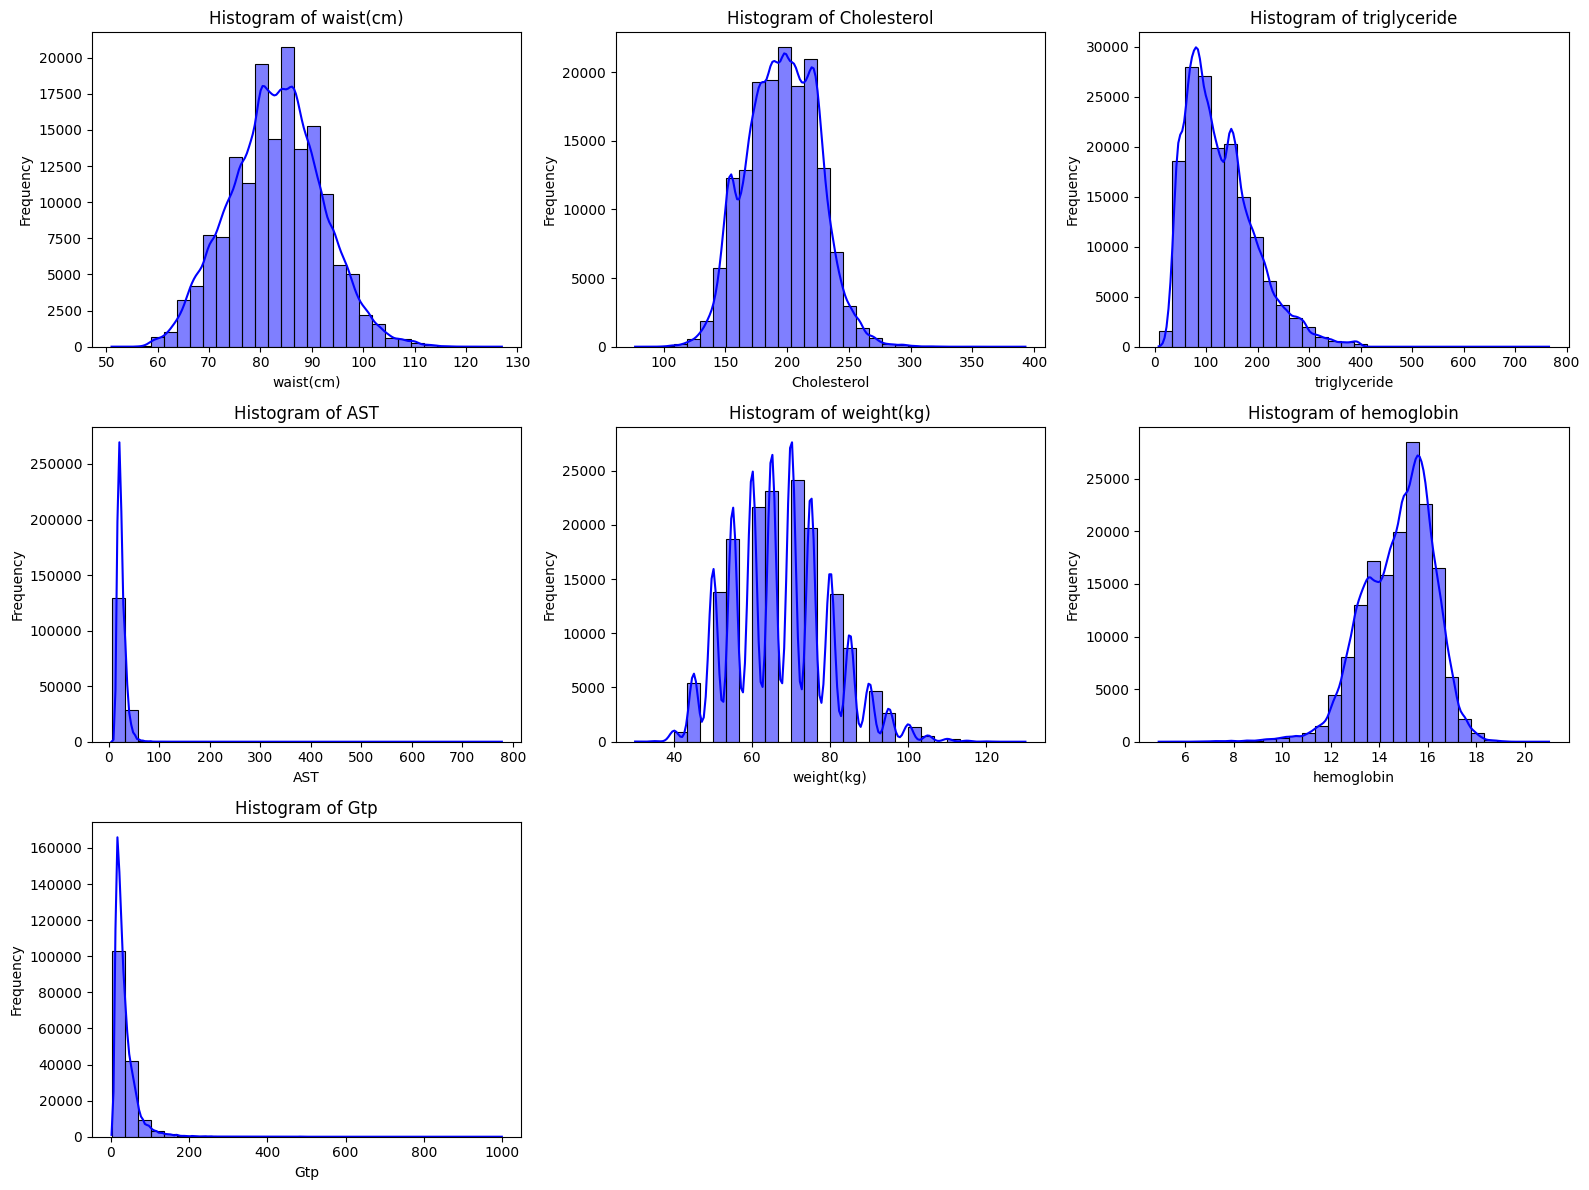

In [22]:
plt.figure(figsize=(16, 12))
for i, feature in enumerate(numerical_features):
    plt.subplot(3, 3, i + 1)
    sns.histplot(df_selected[feature], kde=True, color='blue', bins=30)
    plt.title(f"Histogram of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

skewed features detection graph:
 
triglyceride , Gtp , AST are right skewed

Cholesterol , hemoglobin slightly left skewed

#### Box Plot

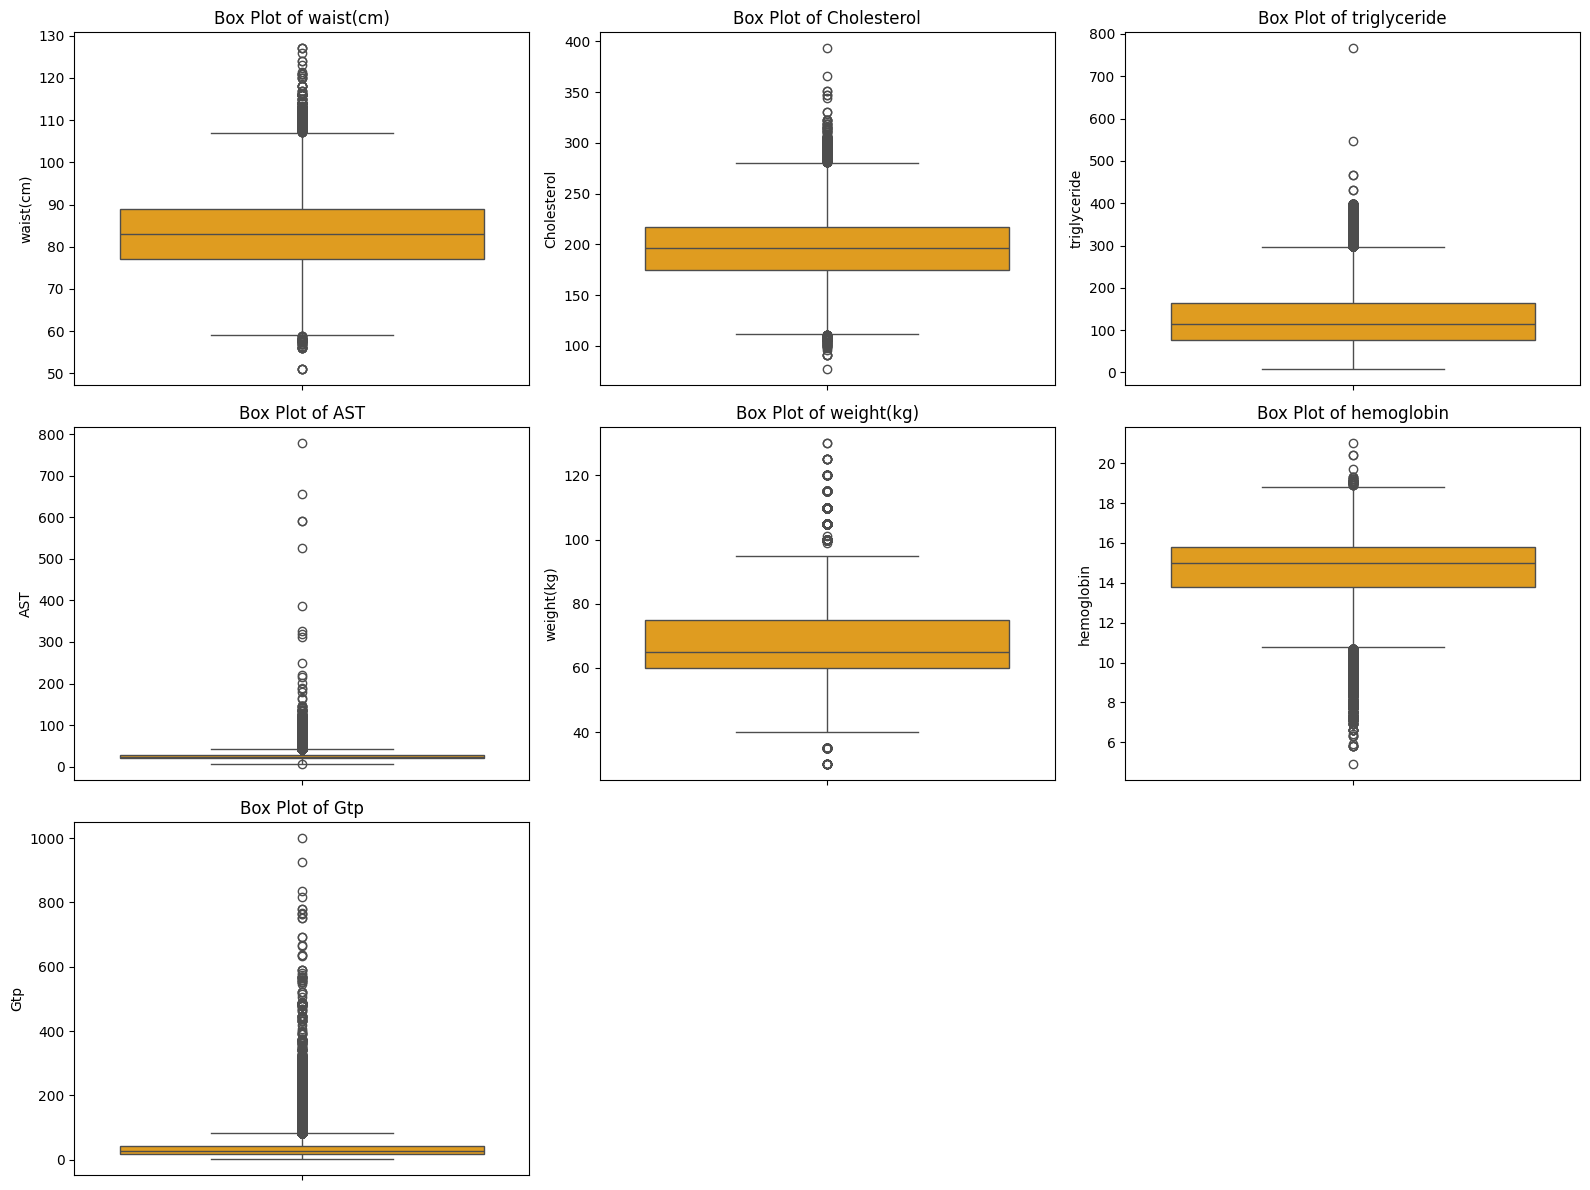

In [23]:
plt.figure(figsize=(16, 12))
for i, feature in enumerate(numerical_features):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df_selected[feature], color='orange')
    plt.title(f"Box Plot of {feature}")
    plt.ylabel(feature)
plt.tight_layout()
plt.show()

box plot proofs the conclusion from the numeric analysis phase (AST,GTP) with most outliers and weight most consistent feature with least outliers

#### Correlation Heatmap

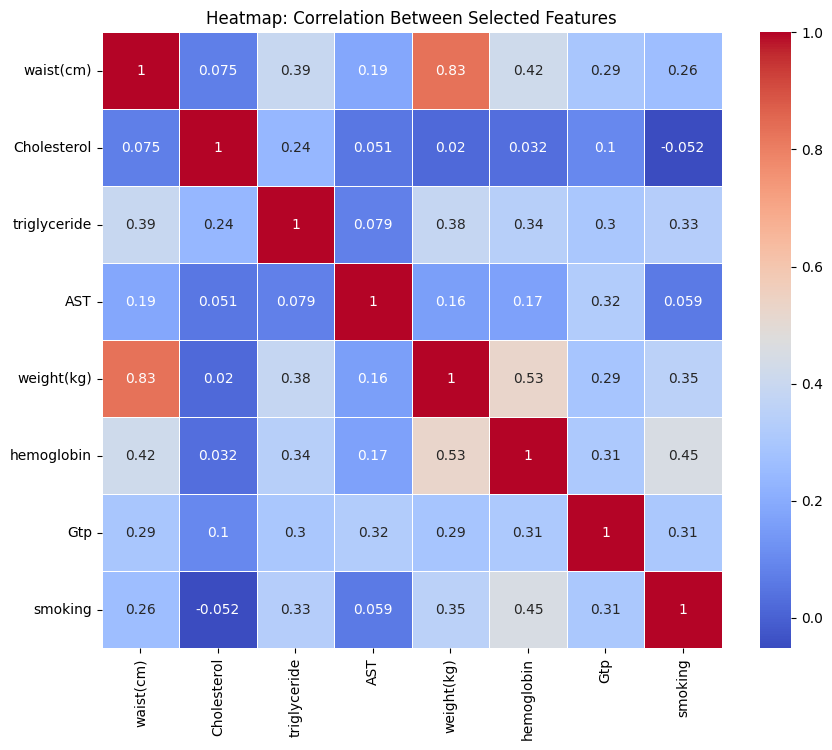

In [24]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_selected.corr(), annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Heatmap: Correlation Between Selected Features")
plt.show()

strongly correlated Features: (weight-waist)

top 3 correlated Features with target: (hemoglobin,weight,triglyceride)

#### Scatter Plot

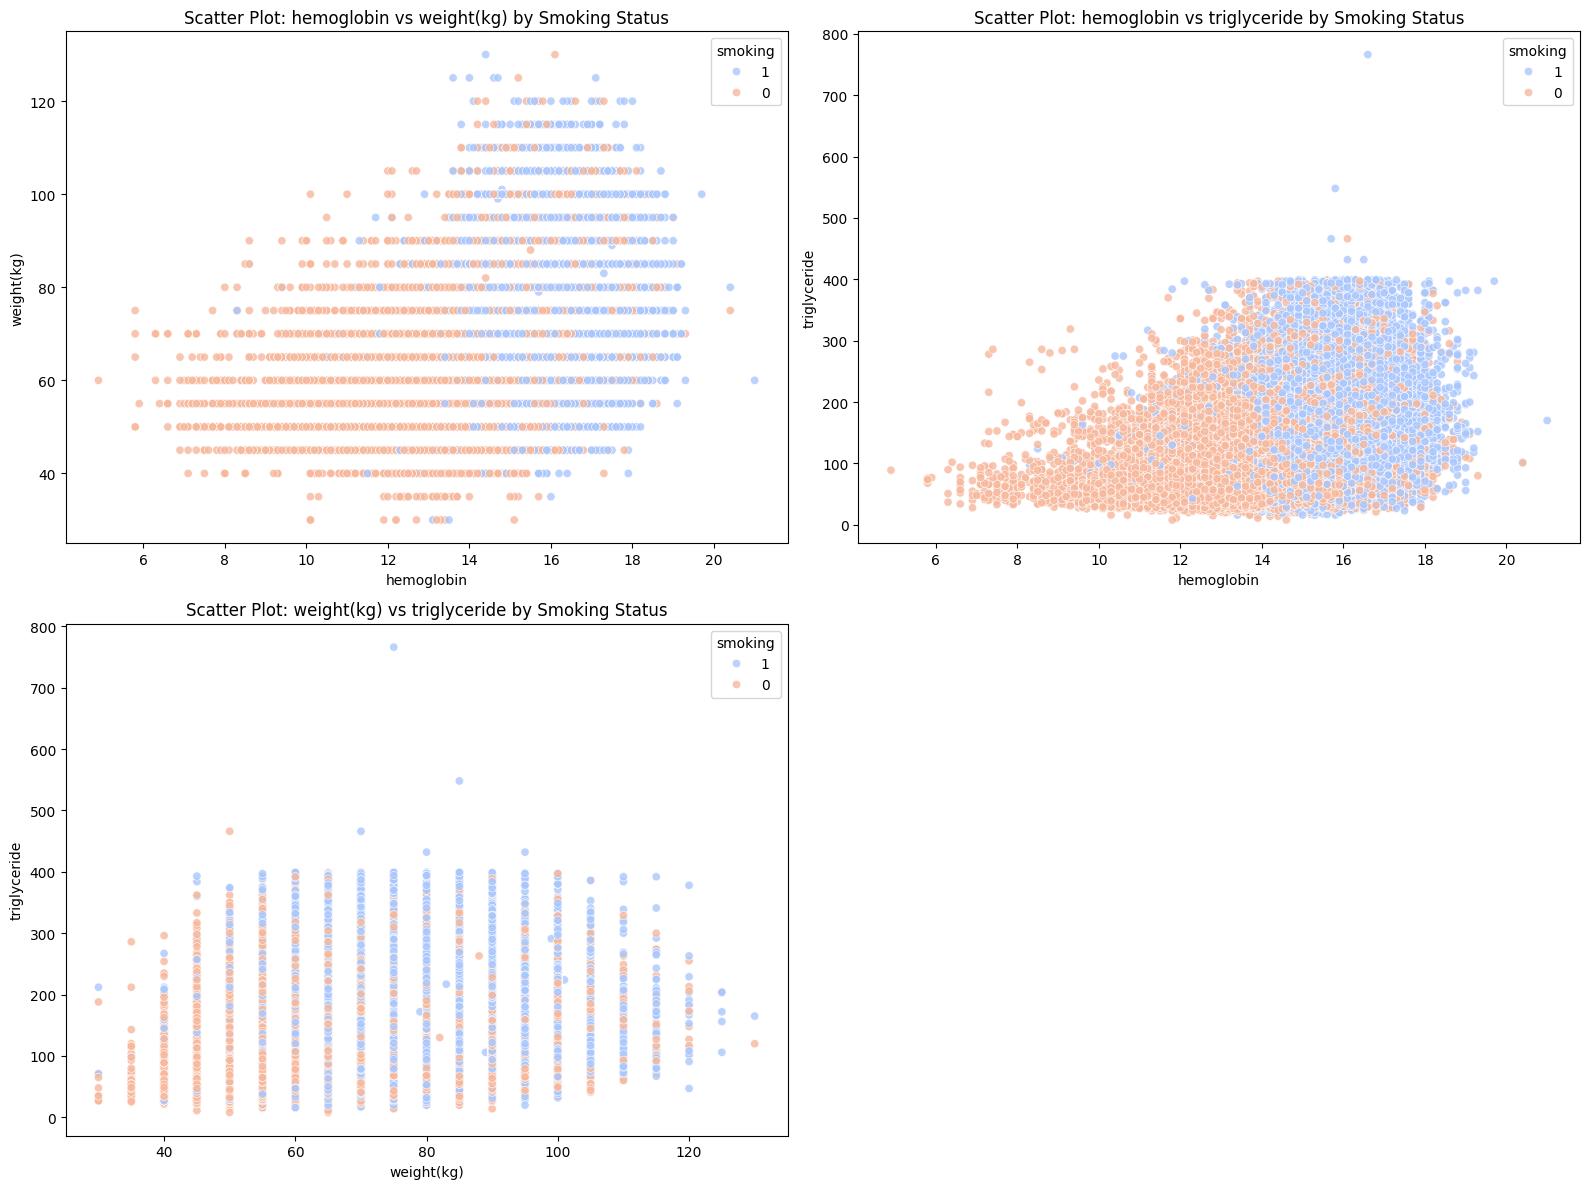

In [25]:
from itertools import combinations

features = ['hemoglobin', 'weight(kg)', 'triglyceride']
pairs = list(combinations(features, 2))
plt.figure(figsize=(16, 12))
for i, (x_feature, y_feature) in enumerate(pairs):
    plt.subplot(2, 2, i + 1)
    sns.scatterplot(
        data=df_selected,
        x=x_feature,
        y=y_feature,
        hue='smoking',
        palette='coolwarm',
        alpha=0.8
    )
    plt.title(f"Scatter Plot: {x_feature} vs {y_feature} by Smoking Status")
    plt.xlabel(x_feature)
    plt.ylabel(y_feature)

plt.tight_layout()
plt.show()

Hemoglobin vs Weight :
Smokers present at higher hemoglobin values
Hemoglobin vs Triglyceride :
Triglyceride increase with hemoglobin, indicating a positive correlation.

#### PCA (Dimensionality Reduction)

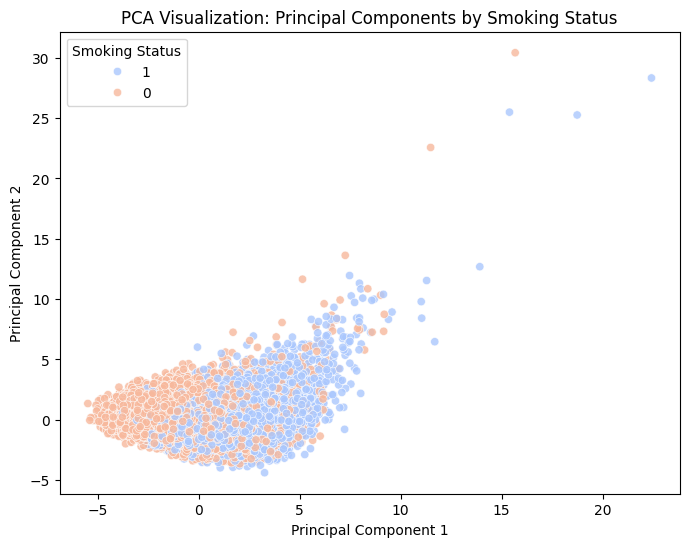

In [26]:
# Apply PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(df_scaled[numerical_features])
pca_df = pd.DataFrame(data=pca_data, columns=["PC1", "PC2"])
pca_df['smoking'] = df_selected['smoking']

# Scatter plot of PCA results
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue='smoking', palette='coolwarm', alpha=0.8)
plt.title("PCA Visualization: Principal Components by Smoking Status")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Smoking Status")
plt.show()

There is partial separation between smokers & non-smokers along the Principal Component 1 axis

There are outliers with high values along PC1 and PC2

#### Pair Plot

<Figure size 1200x800 with 0 Axes>

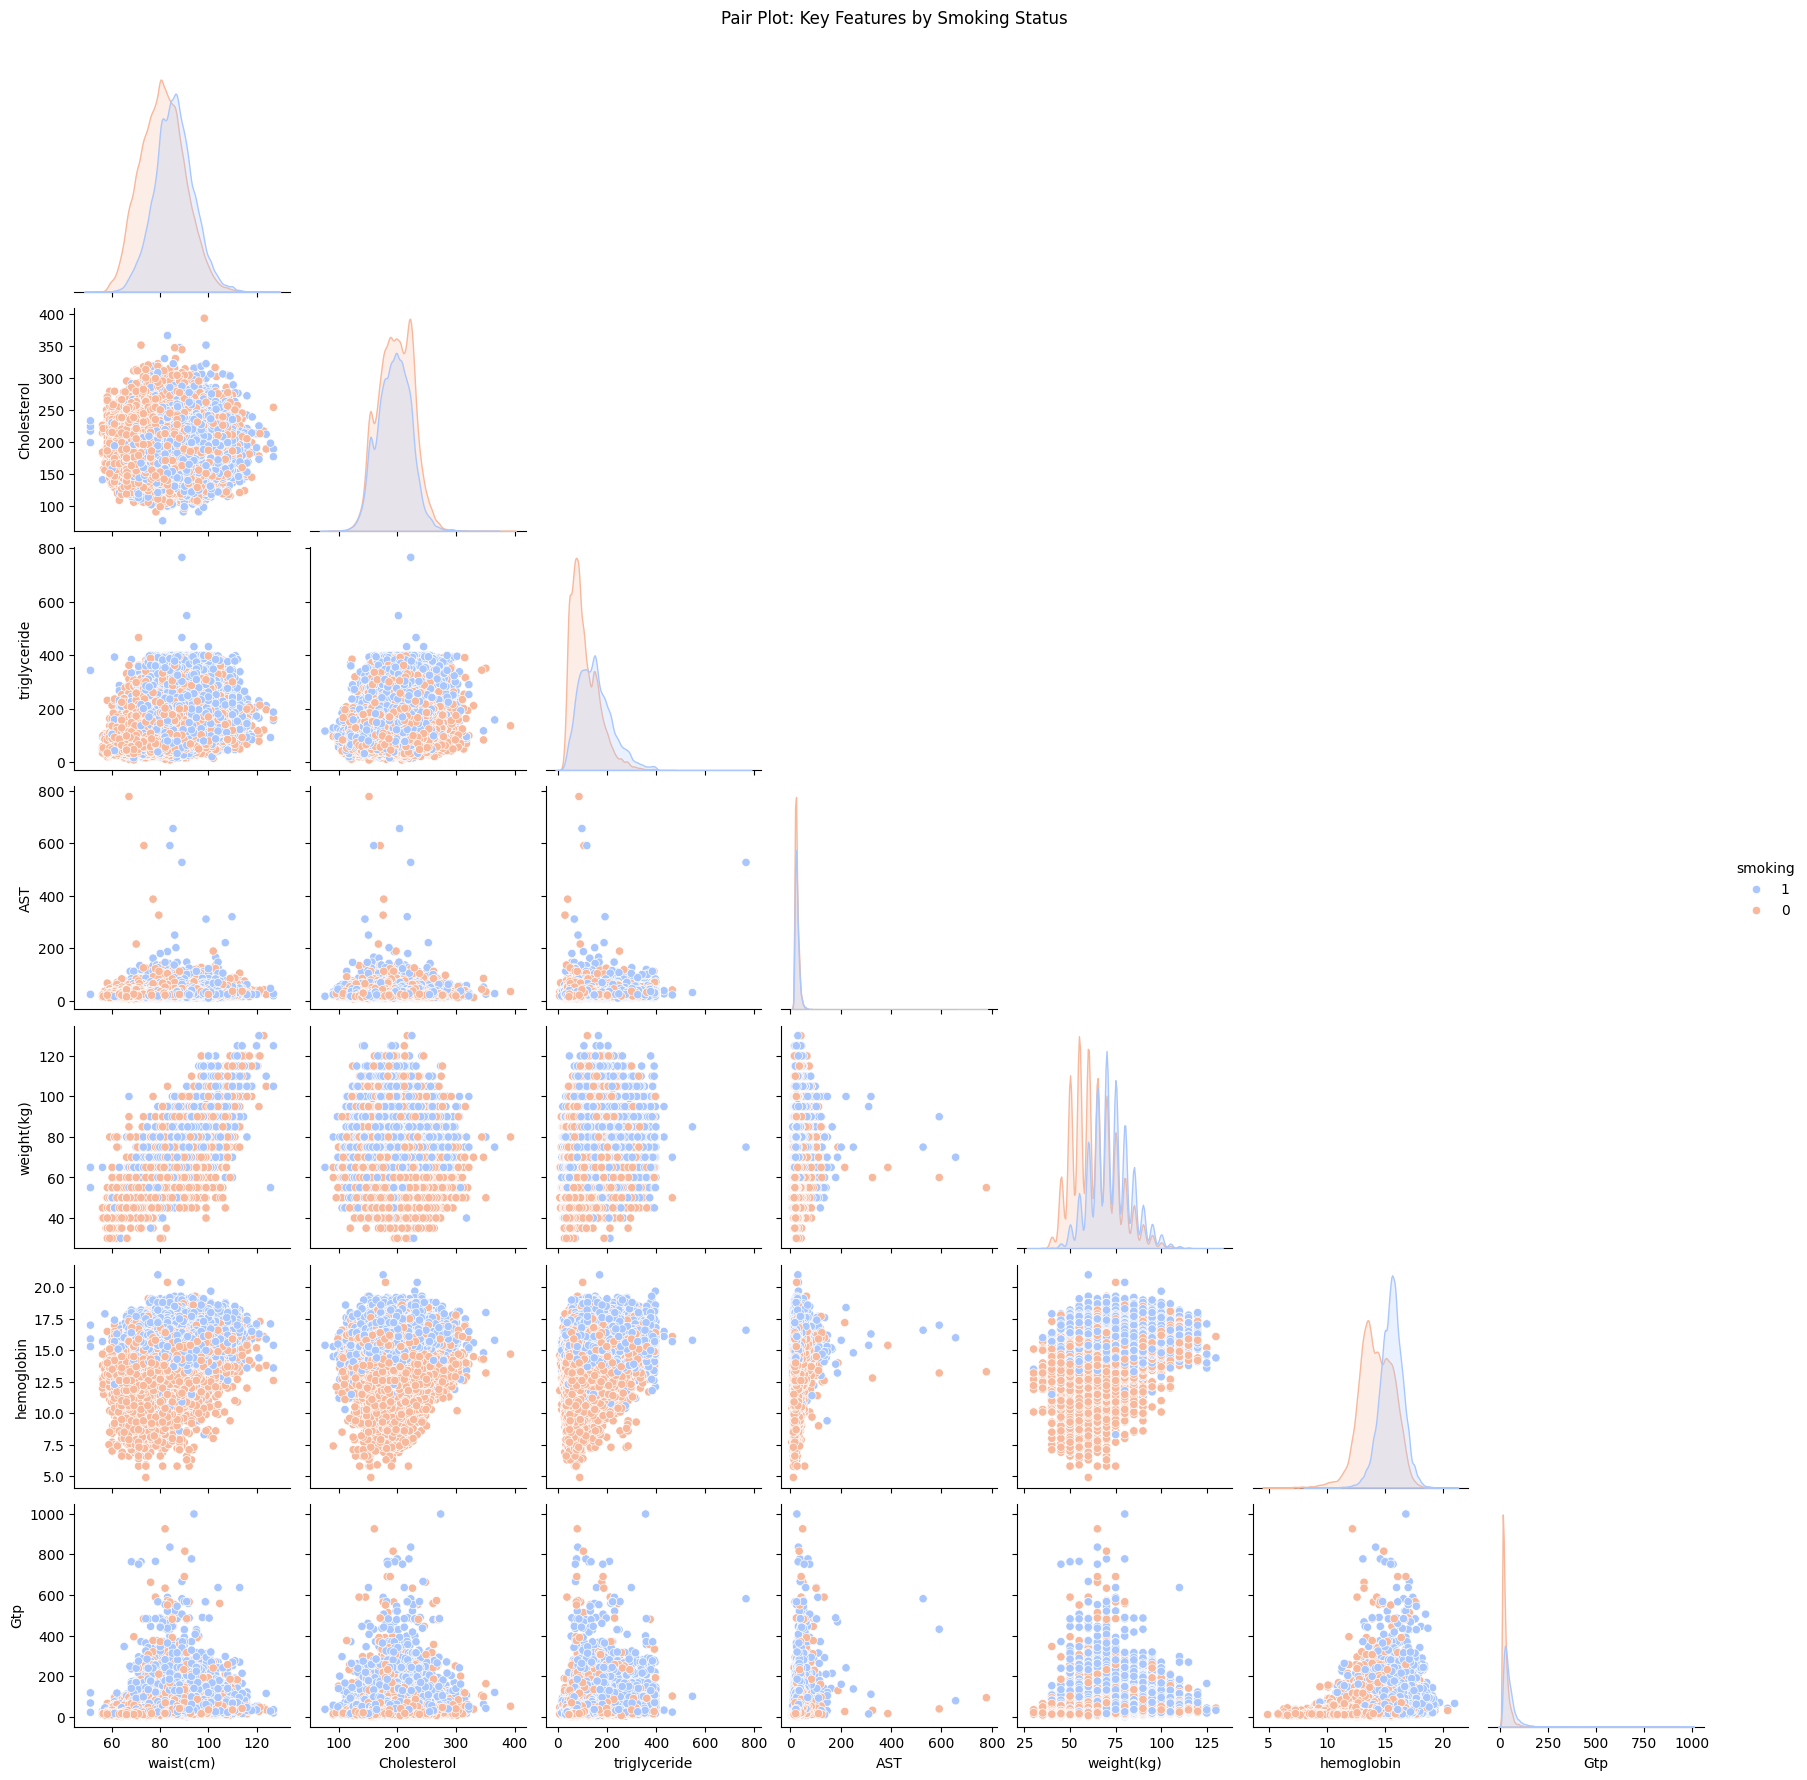

In [27]:
plt.figure(figsize=(12, 8))
sns.pairplot(df_selected, vars=numerical_features, hue='smoking', palette='coolwarm', corner=True)
plt.suptitle("Pair Plot: Key Features by Smoking Status", y=1.02)
plt.show()

Hemoglobin: Smokers have higher hemoglobin levels compared to non-smokers

Weight : Both smokers and non-smokers have a similar weight distribution

Hemoglobin vs. Triglyceride: A positive trend is visible for both smokers & non-smokers

# handling Outliers Analysis

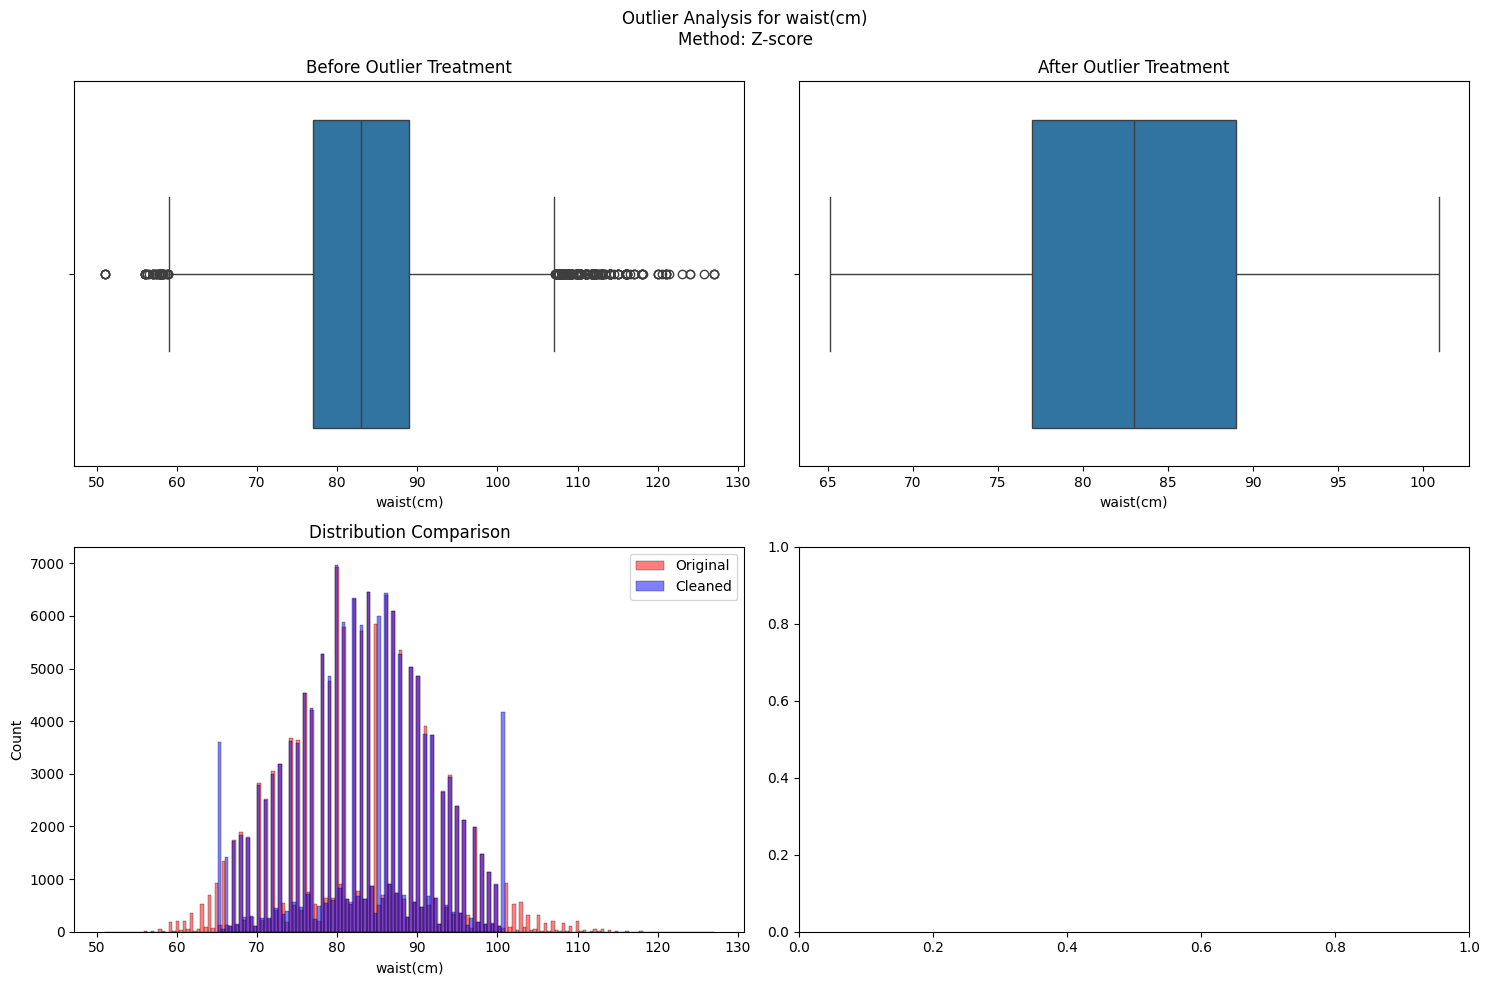

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2348\119079932.py:32: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[252.59008283 139.0022465  139.0022465  ... 252.59008283 252.59008283
 252.59008283]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[outliers, feature] = np.clip(


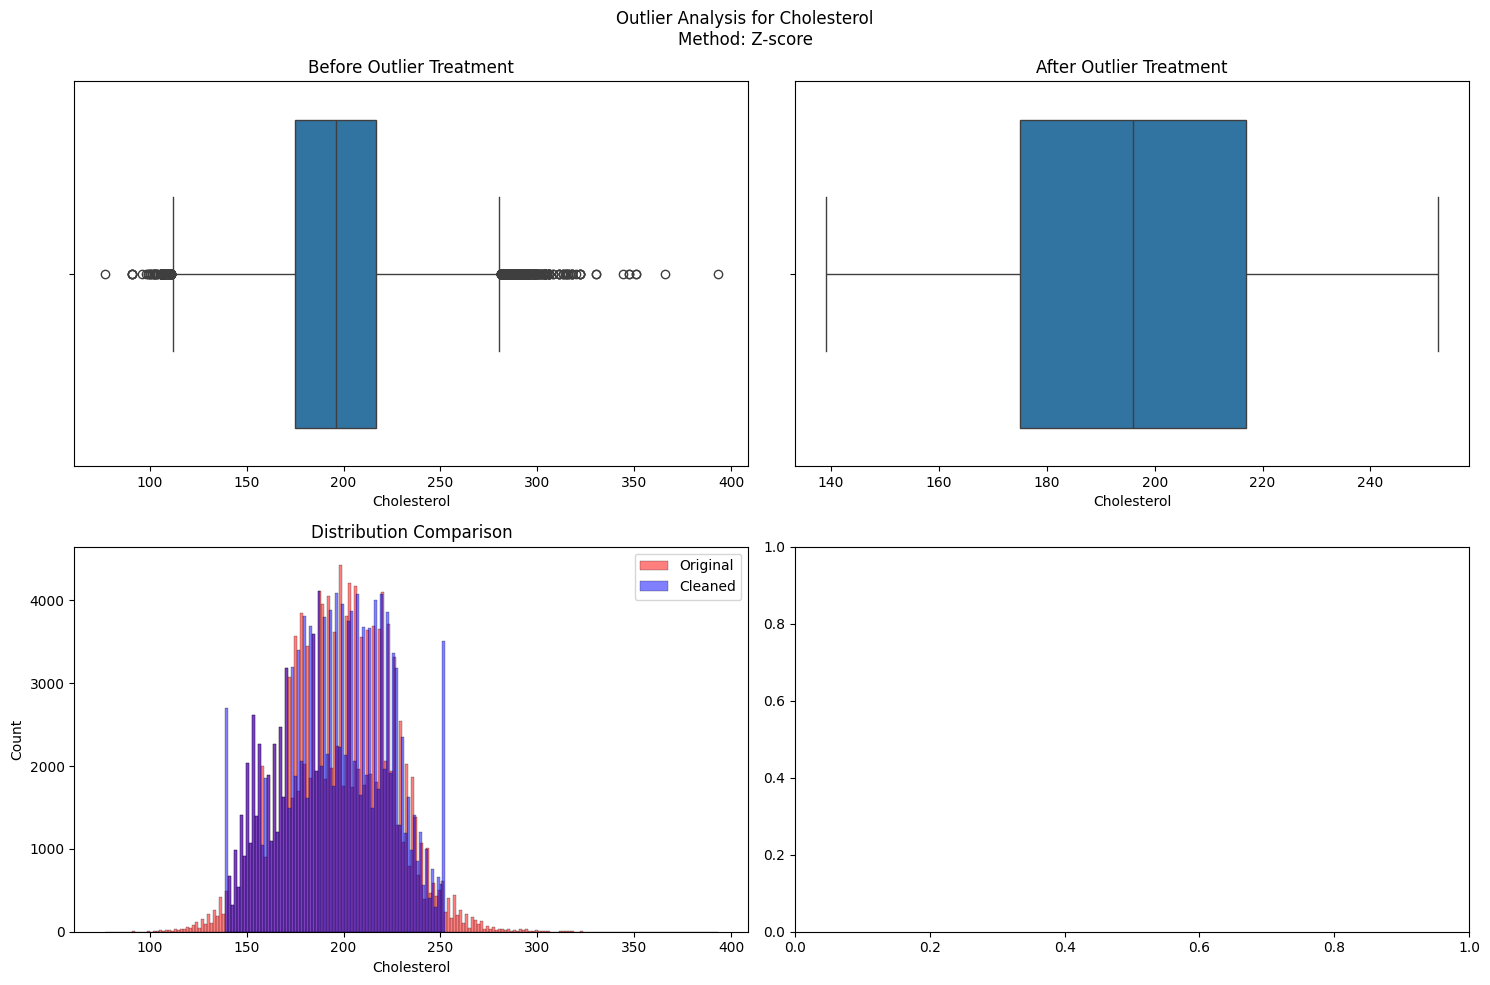

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2348\119079932.py:32: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[259.99402413 259.99402413 259.99402413 ... 259.99402413 259.99402413
 259.99402413]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[outliers, feature] = np.clip(


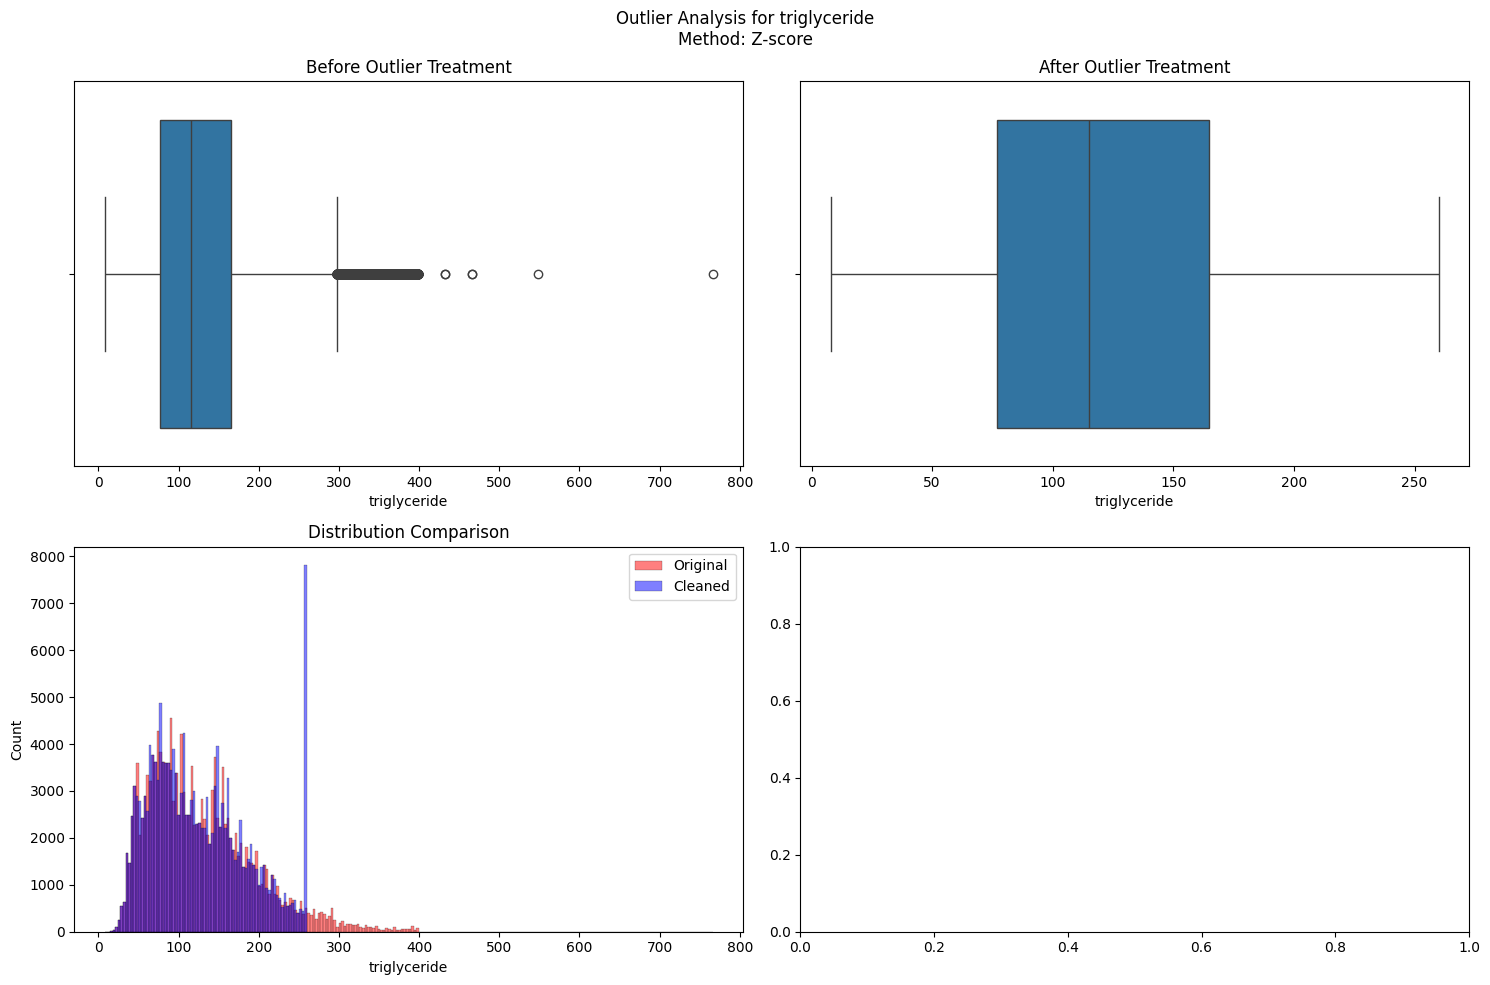

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2348\119079932.py:22: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '6.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[df[feature] < lower_bound, feature] = lower_bound


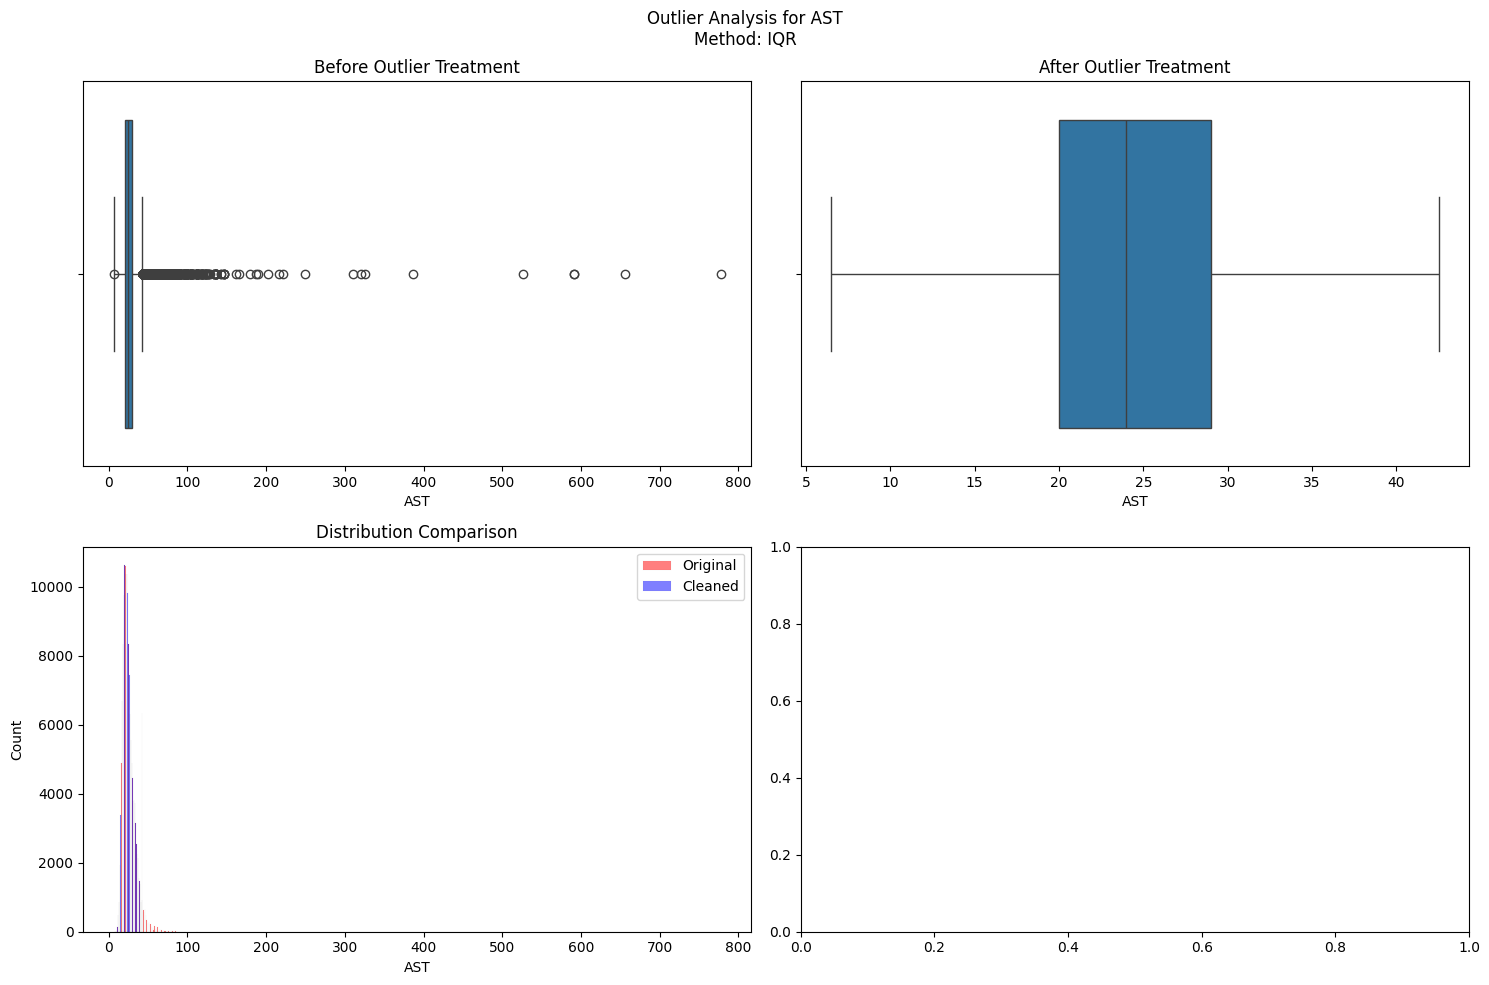

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2348\119079932.py:32: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[92.31605806 92.31605806 41.97126549 ... 92.31605806 92.31605806
 92.31605806]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[outliers, feature] = np.clip(


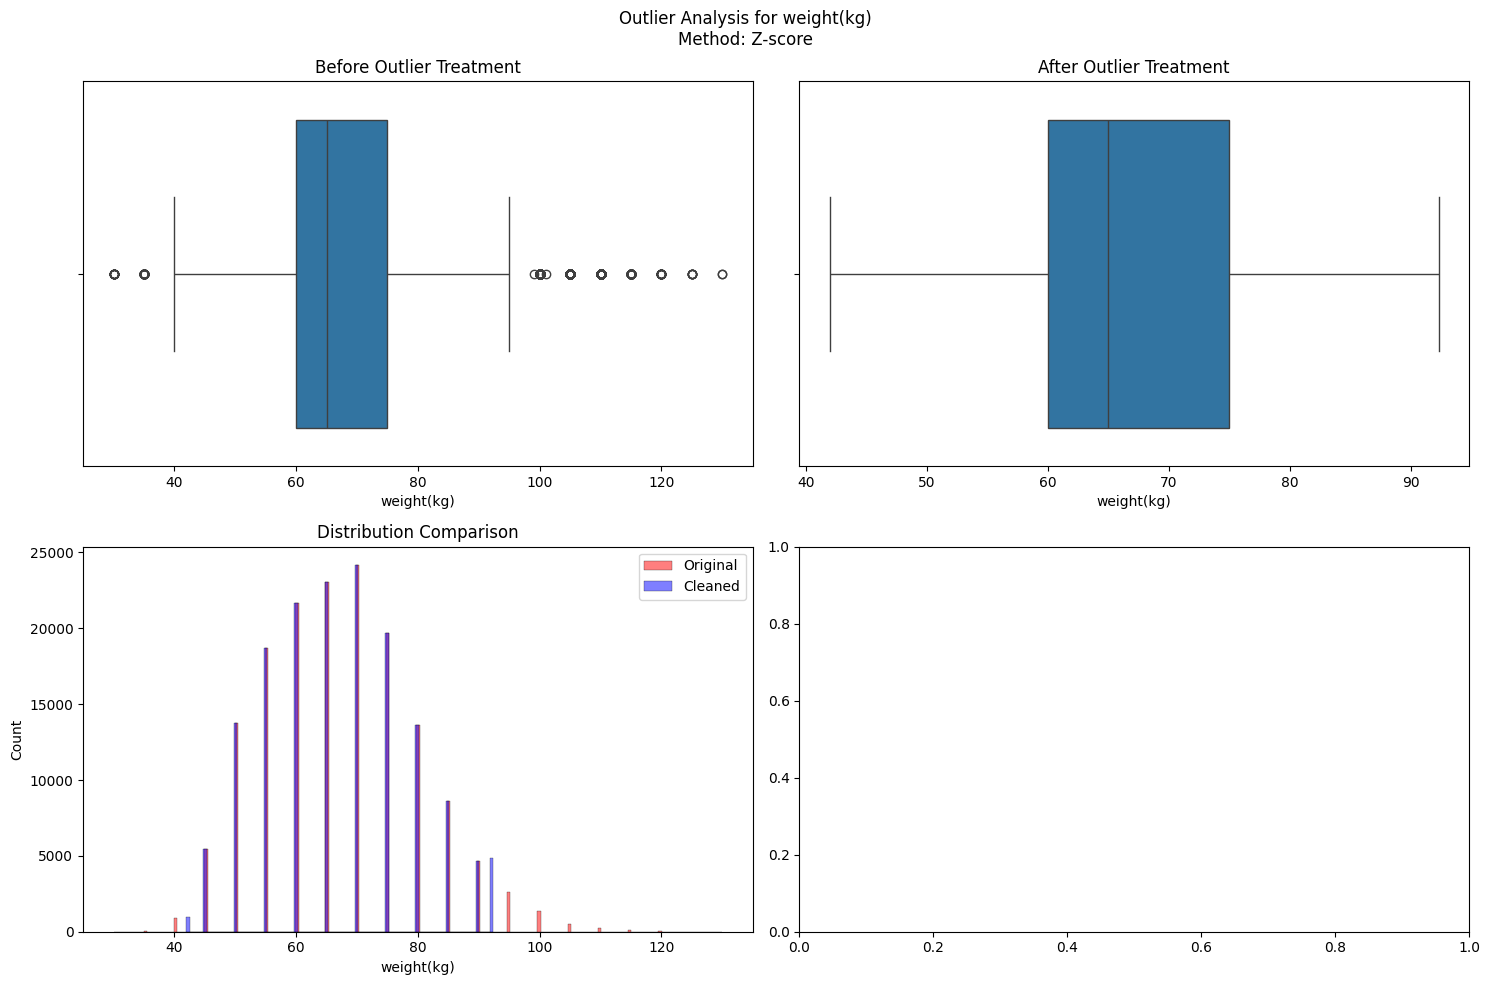

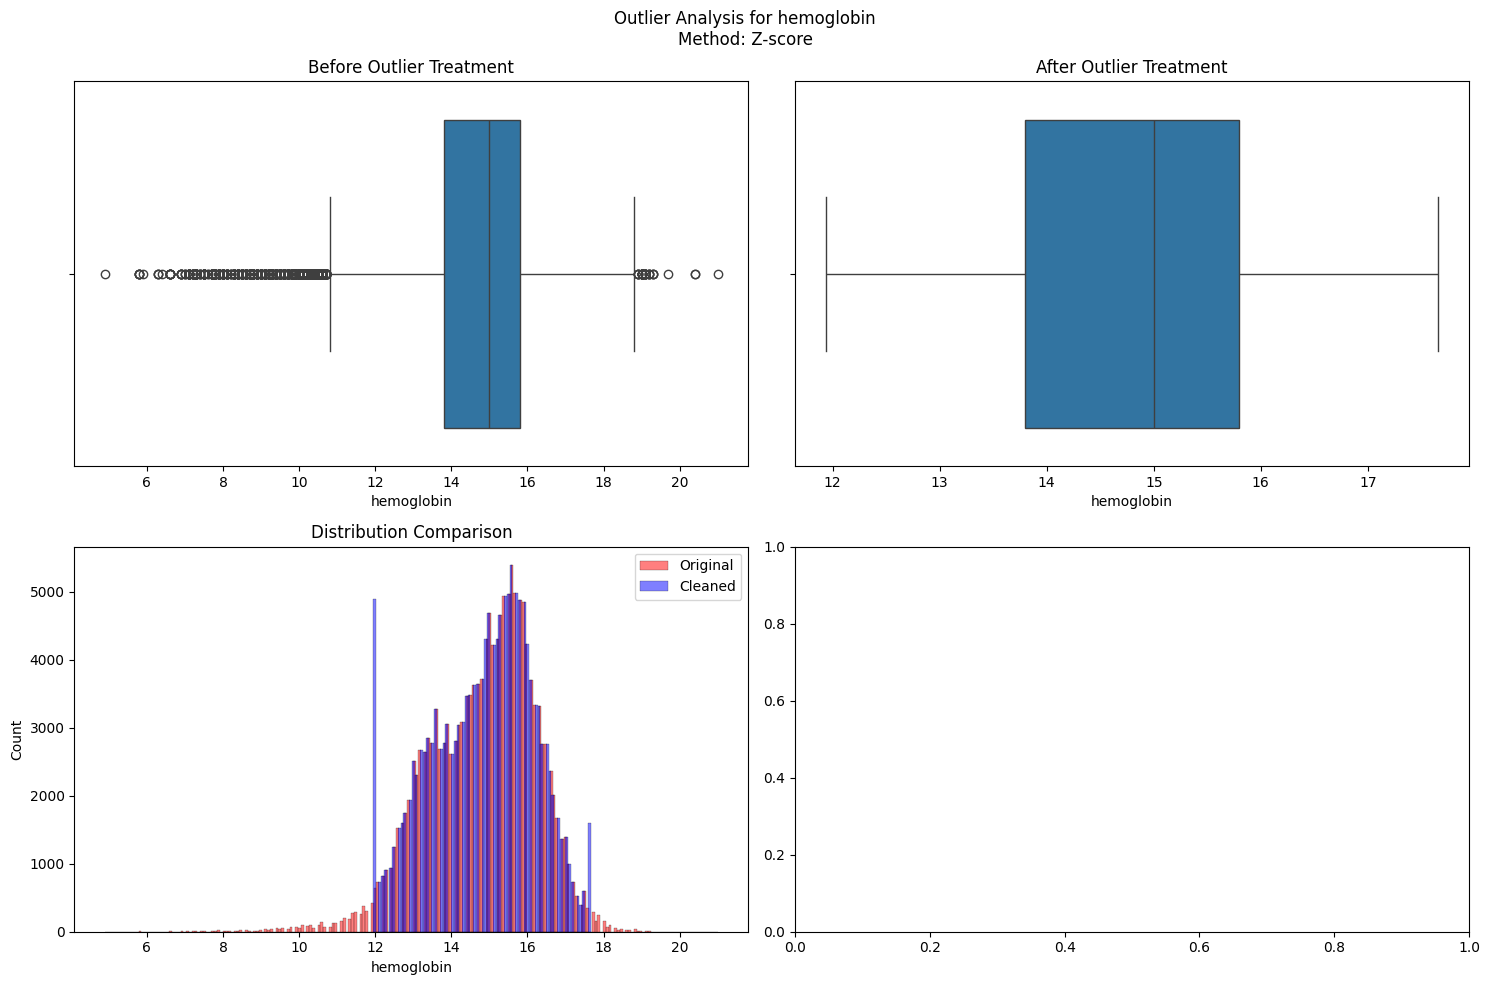

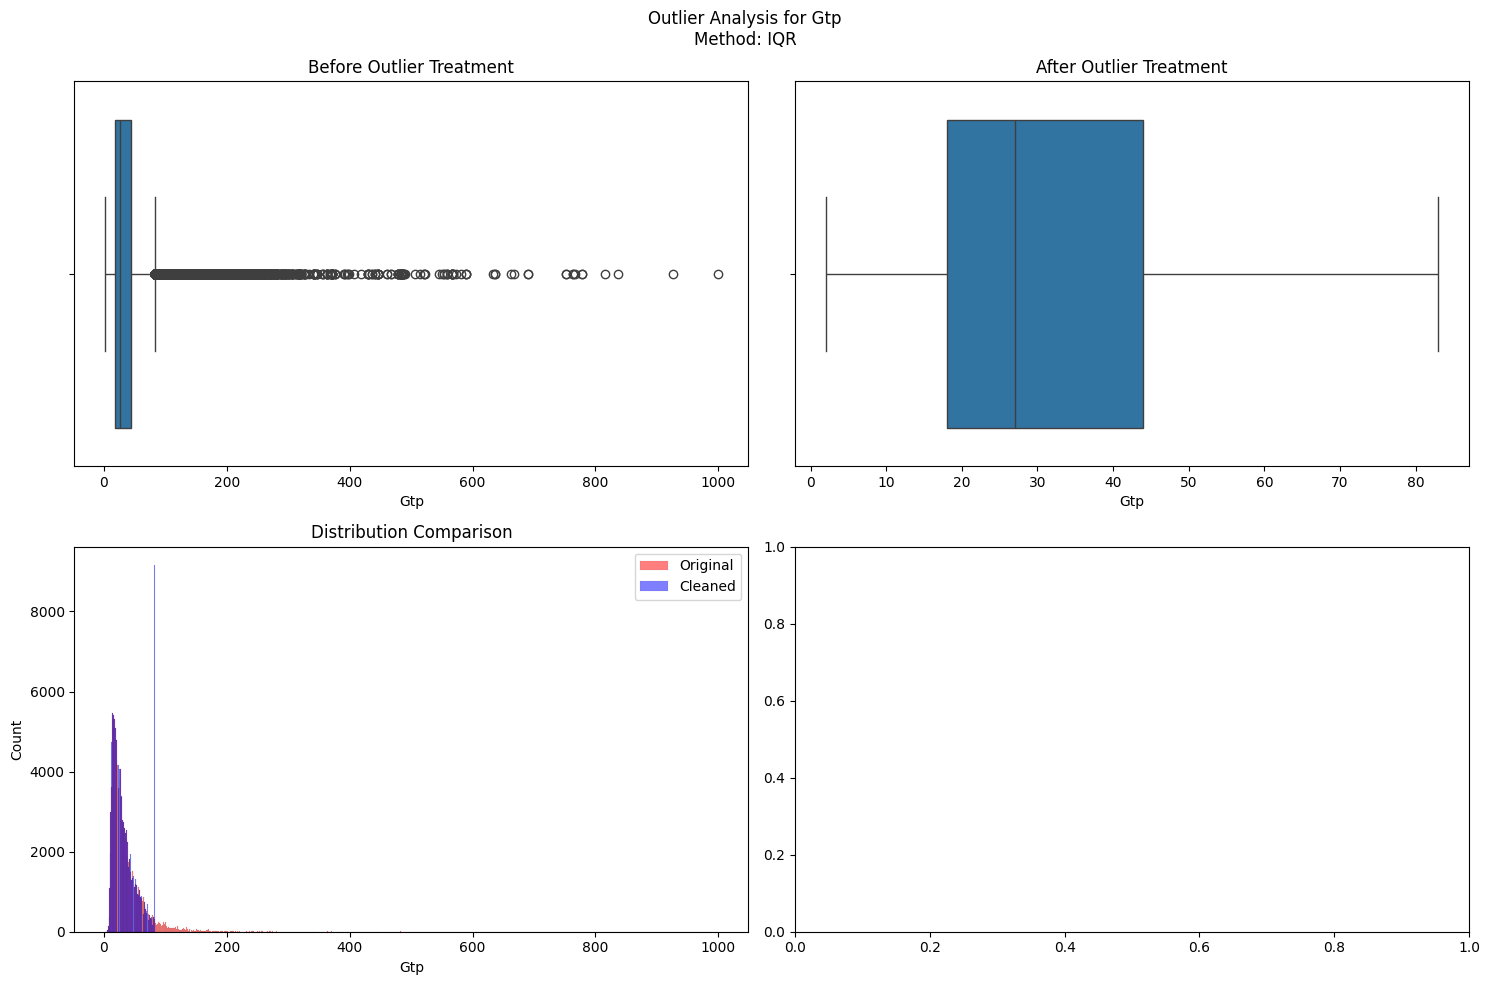

In [28]:
from scipy import stats
import numpy as np

def handle_outliers(df):

    df_clean = df.copy()
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
    if 'smoking' in numerical_features:
        numerical_features.remove('smoking')
  
    for feature in numerical_features:
        skewness = df[feature].skew()
        
        if abs(skewness) > 1:
            Q1 = df[feature].quantile(0.25)
            Q3 = df[feature].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            outliers = (df[feature] < lower_bound) | (df[feature] > upper_bound)
            method = 'IQR'            
            df_clean.loc[df[feature] < lower_bound, feature] = lower_bound
            df_clean.loc[df[feature] > upper_bound, feature] = upper_bound
            
        else:  # Z-score
            z_scores = np.abs(stats.zscore(df[feature]))
            outliers = z_scores > 2
            method = 'Z-score'            
            # capping at ±2 standard deviations
            mean = df[feature].mean()
            std = df[feature].std()
            df_clean.loc[outliers, feature] = np.clip(
                df_clean.loc[outliers, feature],
                mean - 2*std,
                mean + 2*std
            )        
        
        # Visualize the changes
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        fig.suptitle(f'Outlier Analysis for {feature}\nMethod: {method}')
        
        # Original distribution
        sns.boxplot(data=df, x=feature, ax=axes[0,0])
        axes[0,0].set_title('Before Outlier Treatment')
        
        # Cleaned distribution
        sns.boxplot(data=df_clean, x=feature, ax=axes[0,1])
        axes[0,1].set_title('After Outlier Treatment')
        
        # Original vs Cleaned histogram
        sns.histplot(data=df, x=feature, ax=axes[1,0], color='red', alpha=0.5, label='Original')
        sns.histplot(data=df_clean, x=feature, ax=axes[1,0], color='blue', alpha=0.5, label='Cleaned')
        axes[1,0].set_title('Distribution Comparison')
        axes[1,0].legend()        
        
        plt.tight_layout()
        plt.show()
       
    return df_clean
temp = handle_outliers(df_selected)


Uses IQR for skewed features (|skewness| > 1)

Uses Z-score for more normal distributions